<a href="https://colab.research.google.com/github/Stephanie490/DATA201-labs/blob/main/Assignments/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Decision Tree Assignment

Part 1

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [7]:
from ISLP import load_data
Carseats = load_data('Carseats')

Carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [8]:
# Convert Sales into categories: High = 1, Low = 0
Carseats['HighSales'] = (Carseats['Sales'] > 8).astype(int)
Carseats = Carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(Carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [9]:
print(Carseats.isna().sum())

CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
HighSales      0
dtype: int64


In [12]:
X = pd.get_dummies(Carseats.drop(columns='HighSales'), columns=['US', 'Urban','ShelveLoc']).astype(int)
y = Carseats['HighSales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)


print(X_train.shape, X_test.shape)

(280, 14) (120, 14)


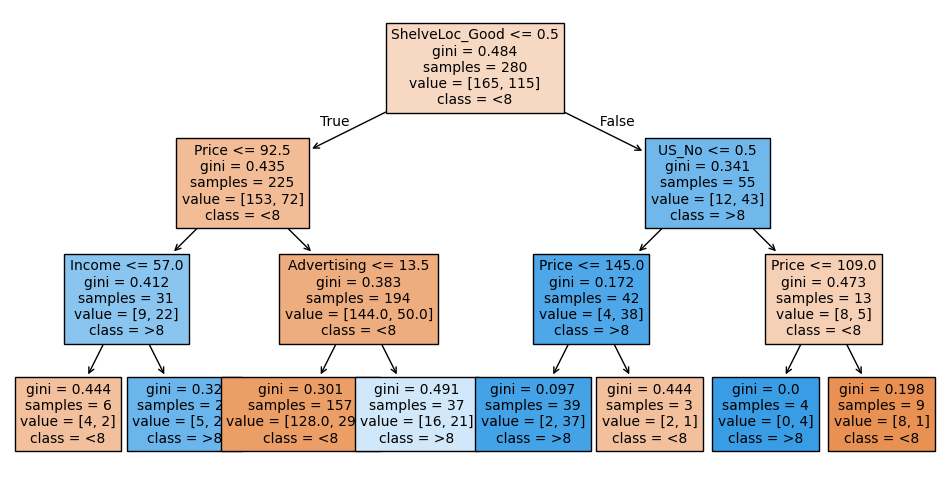

Train accuracy: 0.8
Test accuracy:  0.8


In [13]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0)
tree.fit(X_train, y_train)

#figure's size
plt.figure(figsize=(12, 6))

plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['<8', '>8'], #here "No" is first, because we set it up to be 0. class_names only changes the labels displayed on the tree. It does not change the model's predictions.
          filled=True, #colors nodes based on their predicted class. Stronger colors indicates greater purity
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree.score(X_test, y_test), 3))

Part 2

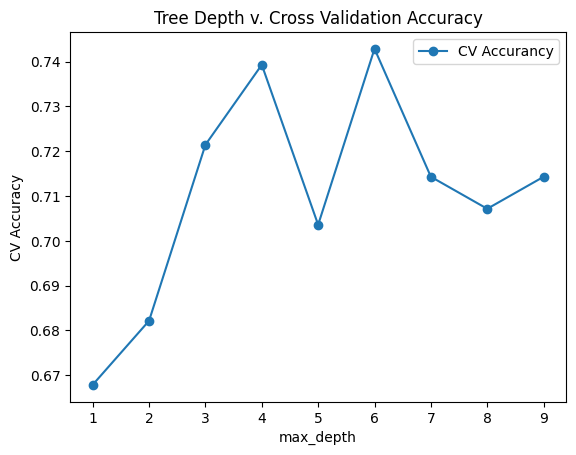

In [18]:
depths = range(1, 10)
cv_acc, n_leaves = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=5).mean())

plt.plot(depths, cv_acc, marker='o', label='CV Accurancy')
plt.xlabel('max_depth'); plt.ylabel('CV Accuracy'); plt.legend()
plt.title('Tree Depth v. Cross Validation Accuracy')
plt.show()

In [25]:
final_T = DecisionTreeClassifier(max_depth=6, random_state=0)
final_T.fit(X_train, y_train)

print('Test accuracy of final tree:', round(final_T.score(X_test, y_test), 3))

Test accuracy of final tree: 0.733


In [22]:
print(export_text(final_T, feature_names=list(X.columns)))

|--- ShelveLoc_Good <= 0.50
|   |--- Price <= 92.50
|   |   |--- Income <= 57.00
|   |   |   |--- ShelveLoc_Medium <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- ShelveLoc_Medium >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Income >  57.00
|   |   |   |--- Price <= 82.00
|   |   |   |   |--- class: 1
|   |   |   |--- Price >  82.00
|   |   |   |   |--- Age <= 65.00
|   |   |   |   |   |--- CompPrice <= 103.00
|   |   |   |   |   |   |--- CompPrice <= 90.50
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |--- CompPrice >  90.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- CompPrice >  103.00
|   |   |   |   |   |   |--- Population <= 120.00
|   |   |   |   |   |   |   |--- Age <= 44.50
|   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |--- Age >  44.50
|   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |--- Population >  120.00
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- A

Part 3

1. Interpreting the tree: Which predictor was selected for the first split (root)? What does
this split tell us about sales?

The 1st predictor selected was ShelveLoc_good. This means that variable results in the lowest impurity/gini

2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?

The graph showed the best max depth is 6 with an accuracy of over 74%. CV is prefered over test accuracy because we should not train using testing data. This can cause bias or iflate accuracy scores.

3. Overfitting: Does increasing tree depth always improve cross-validation accuracy?
Explain using your graph

My graph goes up and down the drops at the highest max_depth values. Therefore I do not think high max_depth is associated with a high cross validation score, CV scores tend to decline with overfitting, not due to the max_depth value.


Wrap-up Questions


1. What does a leaf predict in a classification tree? In a regression tree?

In a classification tree it predicts the most common class, and in regression it predicts the mean of training responses

2. Why did the full tree reach 100% training accuracy but do worse on the test set?

Thhe 100% training accuracy can be due to the model memorizing the training data's noise and patterns. It can have a lower testing accuracy due to not performing well on new observations.

3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?

We can restrict the max_depth or min_sample_leaf. In this lab we used cross validation to select the best max_depth

4. Why do we not need to scale features before fitting a tree?

Because it splits one feaature at a time based on thresholds

5. A teammate says "`Age` has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

The importance 0 just means that it did not have a low impurity in comparison to other features. It has nothing to do with how the predictors affect predictions

6. Name one strength and one weakness of a single decision tree that you saw in this lab.

One strength is that decision tress do not require scaling
One weakness is that small shanges in training data(hig variance) can prodoce very different trees. In the lab this was seen when we checked the feature importance.
